In [5]:
!pip install -q -U kaggle

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 126.2/126.2 kB 7.6 MB/s eta 0:00:00


In [2]:
import os
from getpass import getpass

os.environ["KAGGLE_API_TOKEN"] = getpass("Enter your Kaggle API token: ")

Enter your Kaggle API token: ··········


In [6]:
!kaggle competitions files shl-hiring-assessment-2026

Next Page Token = CfDJ8LXGgraiXMNClPzcySXY5U4n5nIKT_SeMYHy9rkvgk1hCzWQkiRQ4df7VwKtQRi0A1US6tZbx9t_P34BCjHJlyCPiTqAACiy7WlEhgt1A8IB2wnVC8XCuQJ7E05Qh_UkdNZ40gxVEdKxK1IQiM-5Flno2gXzJjl9t9FWTw
name                                       size  creationDate                
-----------------------------------  ----------  --------------------------  
Dataset_Final/sample_submission.csv        3726  2026-09-28 03:37:04.989000  
Dataset_Final/test.csv                     3577  2026-09-28 03:37:12.171000  
Dataset_Final/test/audio_0.wav          1443918  2026-09-28 03:37:05.118000  
Dataset_Final/test/audio_1.wav          1441998  2026-09-28 03:37:05.127000  
Dataset_Final/test/audio_10.wav         1441998  2026-09-28 03:37:05.100000  
Dataset_Final/test/audio_100.wav        1441998  2026-09-28 03:37:05.185000  
Dataset_Final/test/audio_101.wav        1361358  2026-09-28 03:37:05.226000  
Dataset_Final/test/audio_102.wav        1918158  2026-09-28 03:37:05.222000  
Dataset_Final/test/audio_103.wa

In [8]:
!mkdir -p /content/shl_data

!kaggle competitions download \
    shl-hiring-assessment-2026 \
    -p /content/shl_data

shl-hiring-assessment-2026.zip: Skipping, found more recently modified local copy (use --force to force download)


In [9]:
!ls -lh /content/shl_data

total 1.3G
-rw-r--r-- 1 root root 1.3G Sep 28 04:46 shl-hiring-assessment-2026.zip


In [10]:
import zipfile
from pathlib import Path

DOWNLOAD_DIR = Path("/content/shl_data")

zip_files = list(DOWNLOAD_DIR.glob("*.zip"))

print("ZIP files found:", zip_files)

ZIP files found: [PosixPath('/content/shl_data/shl-hiring-assessment-2026.zip')]


In [11]:
with zipfile.ZipFile(zip_files[0], "r") as zip_ref:
    zip_ref.extractall("/content/shl_data")

In [12]:
!find /content/shl_data/Dataset_Final -maxdepth 2 -type f | head -20

/content/shl_data/Dataset_Final/test/audio_154.wav
/content/shl_data/Dataset_Final/test/audio_66.wav
/content/shl_data/Dataset_Final/test/audio_11.wav
/content/shl_data/Dataset_Final/test/audio_100.wav
/content/shl_data/Dataset_Final/test/audio_201.wav
/content/shl_data/Dataset_Final/test/audio_112.wav
/content/shl_data/Dataset_Final/test/audio_153.wav
/content/shl_data/Dataset_Final/test/audio_184.wav
/content/shl_data/Dataset_Final/test/audio_76.wav
/content/shl_data/Dataset_Final/test/audio_61.wav
/content/shl_data/Dataset_Final/test/audio_180.wav
/content/shl_data/Dataset_Final/test/audio_175.wav
/content/shl_data/Dataset_Final/test/audio_57.wav
/content/shl_data/Dataset_Final/test/audio_165.wav
/content/shl_data/Dataset_Final/test/audio_198.wav
/content/shl_data/Dataset_Final/test/audio_160.wav
/content/shl_data/Dataset_Final/test/audio_47.wav
/content/shl_data/Dataset_Final/test/audio_123.wav
/content/shl_data/Dataset_Final/test/audio_197.wav
/content/shl_data/Dataset_Final/test/

In [13]:
!du -sh /content/shl_data/Dataset_Final

1.6G	/content/shl_data/Dataset_Final


## Phase 1) Inspect CSV FIles

In [14]:
from pathlib import Path
import pandas as pd

DATA_DIR = Path("/content/shl_data/Dataset_Final")

# Load CSV files
train_df = pd.read_csv(DATA_DIR / "train.csv")
test_df = pd.read_csv(DATA_DIR / "test.csv")
sample_submission = pd.read_csv(DATA_DIR / "sample_submission.csv")

print("Train:", train_df.shape)
print("Test:", test_df.shape)
print("Sample submission:", sample_submission.shape)

print("Train columns:", train_df.columns.tolist())
print("Test columns:", test_df.columns.tolist())
print("Submission columns:", sample_submission.columns.tolist())


display(train_df.head())

display(test_df.head())

display(sample_submission.head())

Train: (769, 2)
Test: (216, 2)
Sample submission: (204, 2)
Train columns: ['filename', 'label']
Test columns: ['filename', 'label']
Submission columns: ['filename', 'label']


,filename,label
0,audio_192.wav,3.0
1,audio_436.wav,3.0
2,audio_447.wav,3.5
3,audio_126.wav,2.0
4,audio_61.wav,2.0


,filename,label
0,audio_128.wav,-1
1,audio_156.wav,-1
2,audio_19.wav,-1
3,audio_108.wav,-1
4,audio_206.wav,-1


,filename,label
0,audio_804.wav,-1
1,audio_1028.wav,-1
2,audio_865.wav,-1
3,audio_774.wav,-1
4,audio_1138.wav,-1


In [15]:
from pathlib import Path

TRAIN_AUDIO_DIR = DATA_DIR / "train"
TEST_AUDIO_DIR = DATA_DIR / "test"

train_audio_files = {p.name for p in TRAIN_AUDIO_DIR.glob("*.wav")}
test_audio_files = {p.name for p in TEST_AUDIO_DIR.glob("*.wav")}

# Filenames mentioned in CSVs
train_csv_files = set(train_df["filename"])
test_csv_files = set(test_df["filename"])
submission_files = set(sample_submission["filename"])

print("===== AUDIO FILE COUNTS =====")
print("Actual train audio files:", len(train_audio_files))
print("Actual test audio files:", len(test_audio_files))

print("\n===== CSV COUNTS =====")
print("Train CSV rows:", len(train_csv_files))
print("Test CSV rows:", len(test_csv_files))
print("Submission rows:", len(submission_files))

print("\n===== TRAIN MAPPING =====")
print("Train CSV files missing from audio folder:",
      len(train_csv_files - train_audio_files))

print("Audio files missing from train CSV:",
      len(train_audio_files - train_csv_files))

print("\n===== TEST MAPPING =====")
print("Test CSV files missing from audio folder:",
      len(test_csv_files - test_audio_files))

print("Audio files missing from test CSV:",
      len(test_audio_files - test_csv_files))

print("\n===== SUBMISSION VS TEST =====")
print("Test files NOT in sample submission:",
      len(test_csv_files - submission_files))

print("Submission files NOT in test CSV:",
      len(submission_files - test_csv_files))

===== AUDIO FILE COUNTS =====
Actual train audio files: 769
Actual test audio files: 216

===== CSV COUNTS =====
Train CSV rows: 769
Test CSV rows: 216
Submission rows: 204

===== TRAIN MAPPING =====
Train CSV files missing from audio folder: 0
Audio files missing from train CSV: 0

===== TEST MAPPING =====
Test CSV files missing from audio folder: 0
Audio files missing from test CSV: 0

===== SUBMISSION VS TEST =====
Test files NOT in sample submission: 191
Submission files NOT in test CSV: 179


In [16]:
print("\nTest files missing from sample submission:")
print(sorted(test_csv_files - submission_files))

print("\nSubmission files not present in test.csv:")
print(sorted(submission_files - test_csv_files))


Test files missing from sample submission:
['audio_0.wav', 'audio_1.wav', 'audio_10.wav', 'audio_100.wav', 'audio_101.wav', 'audio_102.wav', 'audio_103.wav', 'audio_104.wav', 'audio_105.wav', 'audio_106.wav', 'audio_107.wav', 'audio_109.wav', 'audio_11.wav', 'audio_110.wav', 'audio_111.wav', 'audio_112.wav', 'audio_113.wav', 'audio_114.wav', 'audio_115.wav', 'audio_116.wav', 'audio_118.wav', 'audio_119.wav', 'audio_12.wav', 'audio_120.wav', 'audio_121.wav', 'audio_122.wav', 'audio_123.wav', 'audio_124.wav', 'audio_125.wav', 'audio_126.wav', 'audio_127.wav', 'audio_129.wav', 'audio_131.wav', 'audio_132.wav', 'audio_133.wav', 'audio_134.wav', 'audio_135.wav', 'audio_136.wav', 'audio_137.wav', 'audio_138.wav', 'audio_139.wav', 'audio_140.wav', 'audio_141.wav', 'audio_142.wav', 'audio_143.wav', 'audio_144.wav', 'audio_145.wav', 'audio_146.wav', 'audio_147.wav', 'audio_148.wav', 'audio_149.wav', 'audio_15.wav', 'audio_150.wav', 'audio_151.wav', 'audio_152.wav', 'audio_154.wav', 'audio_155.

## Statictics

In [17]:
print("===== LABEL STATISTICS =====")

print("Minimum:", train_df["label"].min())
print("Maximum:", train_df["label"].max())
print("Mean:", train_df["label"].mean())
print("Median:", train_df["label"].median())
print("Std:", train_df["label"].std())

print("\n===== UNIQUE LABELS =====")
print(sorted(train_df["label"].unique()))

print("\n===== LABEL COUNTS =====")
print(train_df["label"].value_counts().sort_index())

===== LABEL STATISTICS =====
Minimum: 0.0
Maximum: 5.0
Mean: 3.3133940182054618
Median: 3.0
Std: 1.23899953424107

===== UNIQUE LABELS =====
[np.float64(0.0), np.float64(1.0), np.float64(1.5), np.float64(2.0), np.float64(2.5), np.float64(3.0), np.float64(3.5), np.float64(4.0), np.float64(4.5), np.float64(5.0)]

===== LABEL COUNTS =====
label
0.0     37
1.0      1
1.5      3
2.0    102
2.5     79
3.0    174
3.5     64
4.0    124
4.5     52
5.0    133
Name: count, dtype: int64


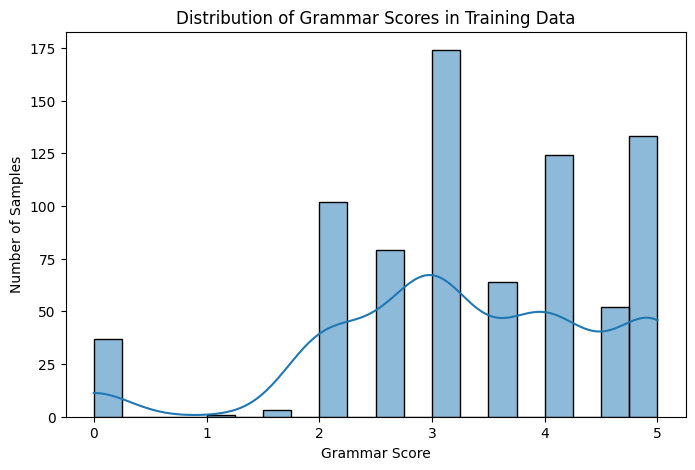

In [19]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))

sns.histplot(
    train_df["label"],
    bins=20,
    kde=True
)

plt.xlabel("Grammar Score")
plt.ylabel("Number of Samples")
plt.title("Distribution of Grammar Scores in Training Data")
plt.show()

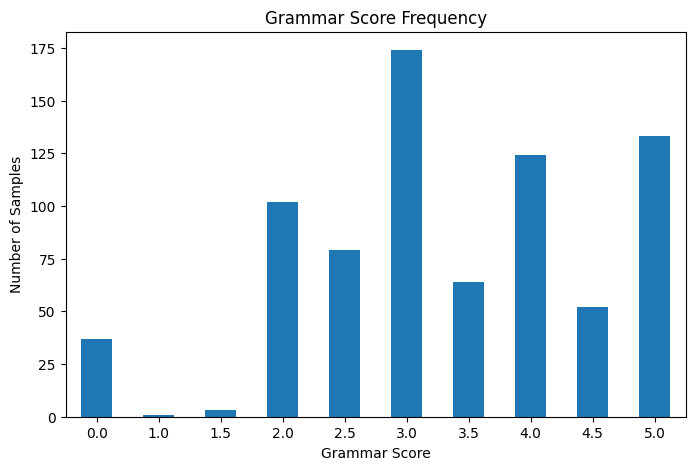

In [20]:
plt.figure(figsize=(8, 5))

train_df["label"].value_counts().sort_index().plot(
    kind="bar"
)

plt.xlabel("Grammar Score")
plt.ylabel("Number of Samples")
plt.title("Grammar Score Frequency")
plt.xticks(rotation=0)
plt.show()

In [21]:
# Missing Values
print("Missing values:")
print(train_df.isnull().sum())

print("\nDuplicate rows:", train_df.duplicated().sum())

print("Duplicate filenames:", train_df["filename"].duplicated().sum())

print("\nTest missing values:")
print(test_df.isnull().sum())

print("Test duplicate filenames:", test_df["filename"].duplicated().sum())

Missing values:
filename    0
label       0
dtype: int64

Duplicate rows: 0
Duplicate filenames: 0

Test missing values:
filename    0
label       0
dtype: int64
Test duplicate filenames: 0


## Audio Inspection

In [22]:
import soundfile as sf
import numpy as np
import pandas as pd

audio_info = []

for filename in train_df["filename"]:
    path = TRAIN_AUDIO_DIR / filename

    info = sf.info(path)

    audio_info.append({
        "filename": filename,
        "duration": info.duration,
        "sample_rate": info.samplerate,
        "channels": info.channels,
        "frames": info.frames
    })

audio_info_df = pd.DataFrame(audio_info)

display(audio_info_df.head())

,filename,duration,sample_rate,channels,frames
0,audio_192.wav,60.508375,16000,1,968134
1,audio_436.wav,60.074688,16000,1,961195
2,audio_447.wav,60.074688,16000,1,961195
3,audio_126.wav,45.060000,16000,1,720960
4,audio_61.wav,45.300000,16000,1,724800


In [23]:
print("===== AUDIO STATISTICS =====")

print("\nDuration:")
print(audio_info_df["duration"].describe())

print("\nSample rates:")
print(audio_info_df["sample_rate"].value_counts())

print("\nChannels:")
print(audio_info_df["channels"].value_counts())

===== AUDIO STATISTICS =====

Duration:
count    769.000000
mean      55.781067
std        7.908964
min       20.060000
25%       54.186687
50%       60.074688
75%       60.074688
max       61.040000
Name: duration, dtype: float64

Sample rates:
sample_rate
16000    769
Name: count, dtype: int64

Channels:
channels
1    769
Name: count, dtype: int64


In [25]:
# Outliers Check

print("Duration < 40 sec:",
      (audio_info_df["duration"] < 40).sum())

print("Duration > 70 sec:",
      (audio_info_df["duration"] > 70).sum())

print("Minimum duration:",
      audio_info_df["duration"].min())

print("Maximum duration:",
      audio_info_df["duration"].max())

Duration < 40 sec: 30
Duration > 70 sec: 0
Minimum duration: 20.06
Maximum duration: 61.04


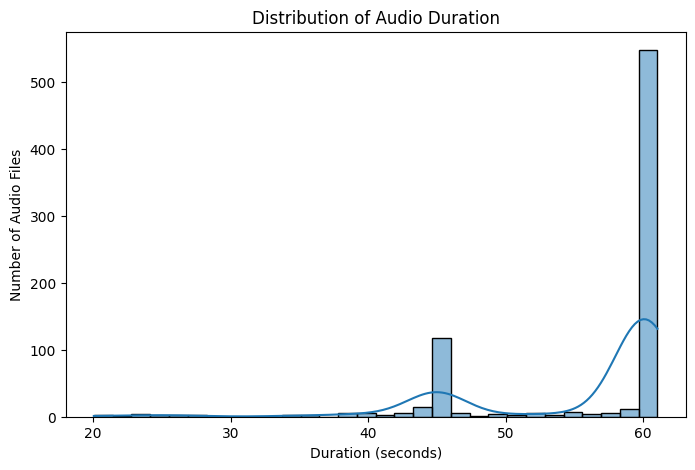

In [26]:
plt.figure(figsize=(8, 5))

sns.histplot(
    audio_info_df["duration"],
    bins=30,
    kde=True
)

plt.xlabel("Duration (seconds)")
plt.ylabel("Number of Audio Files")
plt.title("Distribution of Audio Duration")
plt.show()

## Phase 2) Validation

As the rubric scores are from 1-5, we have 37 samples that have score 0, so we need to identify what actually is the problem

In [27]:
# S1) 0 Score Samples
zero_score_df = train_df[train_df["label"] == 0.0]

print("Number of 0-score samples:", len(zero_score_df))
display(zero_score_df.head(20))

Number of 0-score samples: 37


,filename,label
17,audio_5055.wav,0.0
30,audio_5066.wav,0.0
41,audio_5069.wav,0.0
49,audio_5073.wav,0.0
51,audio_5039.wav,0.0
73,audio_5056.wav,0.0
96,audio_5062.wav,0.0
111,audio_5037.wav,0.0
122,audio_5054.wav,0.0
133,audio_5057.wav,0.0


In [28]:
zero_files = zero_score_df["filename"].tolist()

print(zero_files)

['audio_5055.wav', 'audio_5066.wav', 'audio_5069.wav', 'audio_5073.wav', 'audio_5039.wav', 'audio_5056.wav', 'audio_5062.wav', 'audio_5037.wav', 'audio_5054.wav', 'audio_5057.wav', 'audio_5040.wav', 'audio_5047.wav', 'audio_5050.wav', 'audio_5061.wav', 'audio_5053.wav', 'audio_5065.wav', 'audio_5043.wav', 'audio_5067.wav', 'audio_5038.wav', 'audio_5051.wav', 'audio_5058.wav', 'audio_5052.wav', 'audio_5068.wav', 'audio_5041.wav', 'audio_5059.wav', 'audio_5070.wav', 'audio_5049.wav', 'audio_5042.wav', 'audio_5045.wav', 'audio_5060.wav', 'audio_5064.wav', 'audio_5046.wav', 'audio_5048.wav', 'audio_5071.wav', 'audio_5063.wav', 'audio_5072.wav', 'audio_5044.wav']


All 37 zero-score files have IDs clustered around: audio_5037.wav → audio_5073.wav

That strongly suggests these 37 samples may belong to a special batch/category, rather than being randomly distributed across the dataset.

In [29]:
zero_audio_info = audio_info_df[audio_info_df["filename"].isin(zero_files)].copy()


display(zero_audio_info.sort_values("filename"))

print("\nDuration statistics:")
print(zero_audio_info["duration"].describe())

,filename,duration,sample_rate,channels,frames
111,audio_5037.wav,45.060000,16000,1,720960
338,audio_5038.wav,60.074688,16000,1,961195
51,audio_5039.wav,60.074688,16000,1,961195
142,audio_5040.wav,60.074688,16000,1,961195
403,audio_5041.wav,60.080000,16000,1,961280
485,audio_5042.wav,60.074688,16000,1,961195
309,audio_5043.wav,60.074688,16000,1,961195
691,audio_5044.wav,24.128000,16000,1,386048
490,audio_5045.wav,60.074688,16000,1,961195
529,audio_5046.wav,60.074688,16000,1,961195



Duration statistics:
count    37.000000
mean     57.864160
std       6.992126
min      24.128000
25%      60.074688
50%      60.074688
75%      60.074688
max      61.034687
Name: duration, dtype: float64


In [30]:
nonzero_audio_info = audio_info_df[
    ~audio_info_df["filename"].isin(zero_files)
]

print("Zero-score mean duration:",
      zero_audio_info["duration"].mean())

print("Non-zero mean duration:",
      nonzero_audio_info["duration"].mean())

Zero-score mean duration: 57.86416047297297
Non-zero mean duration: 55.67577399248634


In [31]:
from IPython.display import Audio, display

for filename in zero_files[:3]:
    print(filename)
    display(Audio(str(TRAIN_AUDIO_DIR / filename)))

audio_5055.wav


audio_5066.wav


audio_5069.wav


## Spliiting the Dataset

In [33]:
from sklearn.model_selection import train_test_split

df = train_df.copy()
label_counts = df["label"].value_counts()

df["stratify_group"] = df["label"].apply(lambda x: str(x) if label_counts[x] >= 5 else "rare")

train_split, val_split = train_test_split(df,test_size=0.20,random_state=42,stratify=df["stratify_group"])

train_split = train_split.drop(columns=["stratify_group"])
val_split = val_split.drop(columns=["stratify_group"])

print("Training samples:", len(train_split))
print("Validation samples:", len(val_split))

Training samples: 615
Validation samples: 154


In [34]:
print("===== TRAIN DISTRIBUTION =====")
print(train_split["label"].value_counts().sort_index())

print("\n===== VALIDATION DISTRIBUTION =====")
print(val_split["label"].value_counts().sort_index())

===== TRAIN DISTRIBUTION =====
label
0.0     30
1.0      1
1.5      2
2.0     82
2.5     63
3.0    139
3.5     51
4.0     99
4.5     42
5.0    106
Name: count, dtype: int64

===== VALIDATION DISTRIBUTION =====
label
0.0     7
1.5     1
2.0    20
2.5    16
3.0    35
3.5    13
4.0    25
4.5    10
5.0    27
Name: count, dtype: int64


### S2) Naive baseline

In [35]:
from sklearn.metrics import mean_squared_error
from scipy.stats import pearsonr
import numpy as np

# Mean score from TRAINING split only
baseline_prediction = train_split["label"].mean()

# Predict the same value for every validation sample
baseline_preds = np.full(
    len(val_split),
    baseline_prediction
)

# Validation metrics
baseline_rmse = np.sqrt(
    mean_squared_error(
        val_split["label"],
        baseline_preds
    )
)

baseline_pearson = pearsonr(
    val_split["label"],
    baseline_preds
)[0]

print("Baseline prediction:", baseline_prediction)
print("Validation RMSE:", baseline_rmse)
print("Validation Pearson:", baseline_pearson)

Baseline prediction: 3.310569105691057
Validation RMSE: 1.226855545429296
Validation Pearson: nan


/tmp/ipykernel_12169/1343116598.py:22: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  baseline_pearson = pearsonr(


Our first real audio model needs to get RMSE substantially below 1.2269.

# Experiment 1 (Acoustic Baseline)
Each audio file will be processed one at a time and converted into a small feature vector.

| Feature | What it tells us |
|---|---|
| Duration | How long the person speaks |
| RMS Energy | Loudness / speaking energy |
| Zero Crossing Rate | Signal activity / noisiness |
| Spectral Centroid | Brightness of sound |
| Spectral Bandwidth | Spread of frequencies |
| Spectral Rolloff | Frequency distribution |
| MFCCs | Important characteristics of speech sound |

In [36]:
!pip install -q librosa soundfile

In [37]:
import os
import numpy as np
import pandas as pd
import librosa
import soundfile as sf

from tqdm.auto import tqdm

In [38]:
train_audio_dir = "/content/shl_data/Dataset_Final/train"

sample_file = os.path.join(train_audio_dir, train_split.iloc[0]["filename"])

y, sr = librosa.load(sample_file, sr=16000, mono=True)

print("File:", sample_file)
print("Sample rate:", sr)
print("Number of samples:", len(y))
print("Duration:", len(y) / sr, "seconds")
print("Shape:", y.shape)

File: /content/shl_data/Dataset_Final/train/audio_5051.wav
Sample rate: 16000
Number of samples: 961195
Duration: 60.0746875 seconds
Shape: (961195,)


In [39]:
# Convert Waveform Into Fixed Numerical Feature
def extract_acoustic_features(file_path):
    # S1) Load audio
    y, sr = librosa.load(file_path, sr=16000, mono=True)
    features = {}

    # S2) Duration
    features["duration"] = len(y) / sr

    # S3) RMS Energy
    rms = librosa.feature.rms(y=y)[0]
    features["rms_mean"] = np.mean(rms)
    features["rms_std"] = np.std(rms)

    # S4) Zero Crossing Rate
    zcr = librosa.feature.zero_crossing_rate(y)[0]
    features["zcr_mean"] = np.mean(zcr)
    features["zcr_std"] = np.std(zcr)

    # S5) Spectral Centroid
    centroid = librosa.feature.spectral_centroid(y=y, sr=sr)[0]
    features["centroid_mean"] = np.mean(centroid)
    features["centroid_std"] = np.std(centroid)

    # S6) Spectral Bandwidth
    bandwidth = librosa.feature.spectral_bandwidth(y=y, sr=sr)[0]
    features["bandwidth_mean"] = np.mean(bandwidth)
    features["bandwidth_std"] = np.std(bandwidth)

    # S7) Spectral Rolloff
    rolloff = librosa.feature.spectral_rolloff(y=y, sr=sr)[0]
    features["rolloff_mean"] = np.mean(rolloff)
    features["rolloff_std"] = np.std(rolloff)

    # S8) MFCCs
    mfcc = librosa.feature.mfcc(y=y, sr=sr, n_mfcc=13)

    for i in range(13):
        features[f"mfcc_{i+1}_mean"] = np.mean(mfcc[i])
        features[f"mfcc_{i+1}_std"] = np.std(mfcc[i])

    return features

In [40]:
sample_features = extract_acoustic_features(sample_file)

print("Number of features:", len(sample_features)) # 37 features per audio file
print(sample_features)

Number of features: 37
{'duration': 60.0746875, 'rms_mean': np.float32(0.08045718), 'rms_std': np.float32(0.018333795), 'zcr_mean': np.float64(0.4705954847244409), 'zcr_std': np.float64(0.06237402534222058), 'centroid_mean': np.float64(3910.3897784884634), 'centroid_std': np.float64(209.2100038534849), 'bandwidth_mean': np.float64(2331.3379969611533), 'bandwidth_std': np.float64(78.0331399434412), 'rolloff_mean': np.float64(6748.88927715655), 'rolloff_std': np.float64(134.64531261460778), 'mfcc_1_mean': np.float32(-34.724796), 'mfcc_1_std': np.float32(8.872555), 'mfcc_2_mean': np.float32(0.65218365), 'mfcc_2_std': np.float32(9.28631), 'mfcc_3_mean': np.float32(3.0731168), 'mfcc_3_std': np.float32(6.38137), 'mfcc_4_mean': np.float32(2.462015), 'mfcc_4_std': np.float32(5.288103), 'mfcc_5_mean': np.float32(1.0317814), 'mfcc_5_std': np.float32(4.122511), 'mfcc_6_mean': np.float32(0.42480683), 'mfcc_6_std': np.float32(3.7942247), 'mfcc_7_mean': np.float32(-1.0393858), 'mfcc_7_std': np.float

In [41]:
features_list = []

for filename in tqdm(df["filename"], desc="Extracting acoustic features"):
    file_path = os.path.join(train_audio_dir, filename)

    features = extract_acoustic_features(file_path)
    features["filename"] = filename

    features["label"] = df.loc[df["filename"] == filename, "label"].values[0]

    features_list.append(features)

acoustic_df = pd.DataFrame(features_list)

print("Shape:", acoustic_df.shape)
acoustic_df.head()

Extracting acoustic features:   0%|          | 0/769 [00:00<?, ?it/s]

Shape: (769, 39)


,duration,rms_mean,rms_std,zcr_mean,zcr_std,centroid_mean,centroid_std,bandwidth_mean,bandwidth_std,rolloff_mean,...,mfcc_10_mean,mfcc_10_std,mfcc_11_mean,mfcc_11_std,mfcc_12_mean,mfcc_12_std,mfcc_13_mean,mfcc_13_std,filename,label
0,60.508375,0.031786,0.038404,0.084768,0.053518,979.478539,399.567888,916.472067,261.620566,1770.739688,...,-6.111349,7.005802,-11.947042,8.755231,-8.226156,6.883492,-6.238203,5.747041,audio_192.wav,3.0
1,60.074688,0.068651,0.055423,0.142977,0.127519,1813.837012,1156.460316,1502.301143,495.435560,3277.169030,...,-8.470199,13.448155,-9.261224,11.554407,-9.040758,13.295260,4.751498,13.532232,audio_436.wav,3.0
2,60.074688,0.054421,0.051533,0.146870,0.129777,1652.475254,1207.838332,1500.652559,535.214385,2941.260650,...,-8.570185,16.668097,3.306297,13.158398,-3.113312,11.855078,-0.866495,11.763124,audio_447.wav,3.5
3,45.060000,0.013778,0.012183,0.059477,0.036870,996.631363,471.566967,1177.252185,392.434373,1865.640525,...,-21.515909,15.097207,-12.347360,11.821060,-9.993058,10.599061,-17.710951,11.394984,audio_126.wav,2.0
4,45.300000,0.009330,0.008970,0.169988,0.128430,2278.144095,1068.412091,1630.415181,442.415960,4034.356241,...,-18.795963,16.087770,-8.590364,13.599858,3.873606,10.692766,-17.764481,15.302751,audio_61.wav,2.0


In Above Cell, A single audio is converted into a 37 features numeric data

In [42]:
# Save the acoustic features
acoustic_feature_path = "/content/shl_data/acoustic_features.csv"

acoustic_df.to_csv(acoustic_feature_path, index=False)

print("Saved to:", acoustic_feature_path)
print("Shape:", acoustic_df.shape)

Saved to: /content/shl_data/acoustic_features.csv
Shape: (769, 39)


In [43]:
print(acoustic_df.isnull().sum().sum())

0


Preparing Train/Validation Features

In [45]:
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.metrics import mean_squared_error
from scipy.stats import pearsonr

# Keep only the feature columns
feature_cols = [col for col in acoustic_df.columns if col not in ["filename", "label"]]

# Split using our already-created train/validation filenames
train_acoustic = acoustic_df[acoustic_df["filename"].isin(train_split["filename"])].copy()

val_acoustic = acoustic_df[acoustic_df["filename"].isin(val_split["filename"])].copy()

X_train = train_acoustic[feature_cols]
y_train = train_acoustic["label"]

X_val = val_acoustic[feature_cols]
y_val = val_acoustic["label"]

print("X_train:", X_train.shape)
print("X_val:", X_val.shape)
print("y_train:", y_train.shape)
print("y_val:", y_val.shape)

X_train: (615, 37)
X_val: (154, 37)
y_train: (615,)
y_val: (154,)


We will use 2 Models

Ridge → simple linear relationship

Random Forest → nonlinear relationships

In [46]:
models = {
    "Ridge": Pipeline([
        ("scaler", StandardScaler()),
        ("model", Ridge(alpha=10.0))
    ]),

    "Random Forest": RandomForestRegressor(
        n_estimators=300,
        max_depth=None,
        min_samples_leaf=3,
        random_state=42,
        n_jobs=-1
    )
}

results = []

for name, model in models.items():

    model.fit(X_train, y_train)

    train_pred = model.predict(X_train)
    val_pred = model.predict(X_val)

    train_rmse = np.sqrt(mean_squared_error(y_train, train_pred))
    val_rmse = np.sqrt(mean_squared_error(y_val, val_pred))
    val_pearson = pearsonr(y_val, val_pred)[0]

    results.append({
        "Model": name,
        "Train RMSE": train_rmse,
        "Validation RMSE": val_rmse,
        "Validation Pearson": val_pearson
    })

results_df = pd.DataFrame(results)

results_df

,Model,Train RMSE,Validation RMSE,Validation Pearson
0,Ridge,0.814647,0.840735,0.729495
1,Random Forest,0.373299,0.765791,0.782325


In [47]:
best_model = models["Random Forest"]

val_pred = best_model.predict(X_val)

print("Min prediction:", val_pred.min())
print("Max prediction:", val_pred.max())
print("Actual min:", y_val.min())
print("Actual max:", y_val.max())

Min prediction: 0.0
Max prediction: 4.855307539682539
Actual min: 0.0
Actual max: 5.0


Random Forest wins:
- RMSE: 0.766 vs baseline 1.227 → major improvement
- Pearson: 0.782 → strong correlation
- Predictions stay naturally within approximately 0–5
- Train RMSE = 0.373 vs validation = 0.766, so there is some overfitting, but not catastrophic.

Most importantly:
Acoustic information alone already contains a strong signal for grammar scoring.

Adding Some More Relevant Features
1. Pitch
- mean fundamental frequency
- pitch variability
2. Silence / pauses
- proportion of low-energy frames
- number of speech/silence transitions
3. Speaking behavior
- estimated voiced-frame ratio
These can capture fluency and speaking characteristics that the basic MFCC features don't explicitly represent.

In [48]:
def extract_speech_features(file_path):
    y, sr = librosa.load(file_path, sr=16000, mono=True)

    features = {}

    # Pitch / fundamental frequency
    f0, voiced_flag, voiced_prob = librosa.pyin(
        y,
        fmin=librosa.note_to_hz("C2"),
        fmax=librosa.note_to_hz("C7"),
        sr=sr
    )

    valid_f0 = f0[~np.isnan(f0)]

    if len(valid_f0) > 0:
        features["pitch_mean"] = np.mean(valid_f0)
        features["pitch_std"] = np.std(valid_f0)
        features["pitch_min"] = np.min(valid_f0)
        features["pitch_max"] = np.max(valid_f0)
    else:
        features["pitch_mean"] = 0
        features["pitch_std"] = 0
        features["pitch_min"] = 0
        features["pitch_max"] = 0

    # Voiced ratio
    features["voiced_ratio"] = np.mean(voiced_flag)

    # Energy-based silence estimate
    rms = librosa.feature.rms(y=y)[0]

    threshold = np.percentile(rms, 20)

    silence_ratio = np.mean(rms < threshold)

    features["silence_ratio"] = silence_ratio

    # Silence transitions
    is_silent = rms < threshold

    transitions = np.sum(is_silent[1:] != is_silent[:-1])

    features["silence_transitions"] = transitions

    return features

In [49]:
speech_features = extract_speech_features(sample_file)

print("Number of speech features:", len(speech_features))
print(speech_features)

Number of speech features: 7
{'pitch_mean': np.float64(96.74109373168822), 'pitch_std': np.float64(29.438475754220764), 'pitch_min': np.float64(65.40639132514966), 'pitch_max': np.float64(169.64319079487348), 'voiced_ratio': np.float64(0.4014909478168264), 'silence_ratio': np.float64(0.20021299254526093), 'silence_transitions': np.int64(250)}


In [50]:
# # Extract for all 769 Features
# speech_features_list = []

# for filename in tqdm(df["filename"], desc="Extracting speech features"):
#     file_path = os.path.join(train_audio_dir, filename)

#     features = extract_speech_features(file_path)
#     features["filename"] = filename

#     speech_features_list.append(features)

# speech_df = pd.DataFrame(speech_features_list)

# print("Speech features shape:", speech_df.shape)

Extracting speech features:   0%|          | 0/769 [00:00<?, ?it/s]

SystemError: CPUDispatcher(<function _viterbi at 0x78eb42737920>) returned a result with an exception set

In [ ]:
# # Merge With Previous
# acoustic_enhanced_df = acoustic_df.merge(
#     speech_df,
#     on="filename",
#     how="left"
# )

# print("Enhanced feature shape:", acoustic_enhanced_df.shape)
# print("Missing values:", acoustic_enhanced_df.isnull().sum().sum())

### Experiment 1 — Acoustic Baseline Summary
Objective: Build a simple acoustic-only model to establish a strong baseline before adding linguistic/Whisper features.
1. Acoustic Features Extracted
For each of the 769 training audio files, we extracted 37 acoustic features:
- Duration
- RMS energy — mean & standard deviation
- Zero Crossing Rate — mean & standard deviation
- Spectral Centroid — mean & standard deviation
- Spectral Bandwidth — mean & standard deviation
- Spectral Rolloff — mean & standard deviation
- 13 MFCCs — mean & standard deviation for each coefficient
Result:
acoustic_df shape = (769, 39)

39 = 37 features + filename + label
The extracted features were saved to:
/content/shl_data/acoustic_features.csv

2. Models Tested
Using the same 80/20 stratified validation split (random_state=42):
Model	Train RMSE	Validation RMSE	Validation Pearson
Ridge	0.815	0.841	0.729
Random Forest	0.373	0.766	0.782


The constant-mean baseline had:
Validation RMSE = 1.227
Pearson = N/A

Therefore, the acoustic Random Forest gives a large improvement over the naive baseline.
3. Prediction Range
Random Forest validation predictions:
Minimum = 0.0
Maximum = 4.855

So predictions were naturally within the expected 0–5 range.
4. Attempted Acoustic Enhancement
We attempted to add 7 speech-behavior features:
- Pitch mean
- Pitch standard deviation
- Pitch minimum
- Pitch maximum
- Voiced ratio
- Silence ratio
- Silence transitions
These required librosa.pyin() pitch extraction.
However, extraction was extremely slow:
169 / 769 files after ~10 minutes
Estimated total ≈ 45+ minutes

Colab also showed a low compute balance warning.
Decision
We stopped the pitch extraction because the computational cost was too high relative to the potential benefit.
The original acoustic branch is therefore considered complete with Random Forest as the current acoustic baseline:

In [52]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [53]:
import os

checkpoint_dir = "/content/drive/MyDrive/SHL_SpokenV1/checkpoints"
os.makedirs(checkpoint_dir, exist_ok=True)

print("Checkpoint directory:", checkpoint_dir)

Checkpoint directory: /content/drive/MyDrive/SHL_SpokenV1/checkpoints


## Experiment 2 (Linguistic - Whisper)

In [ ]:
!pip install -q openai-whisper

In [55]:
import whisper
import torch

device = "cuda" if torch.cuda.is_available() else "cpu"

print("Device:", device)
print("CUDA available:", torch.cuda.is_available())

Device: cuda
CUDA available: True


In [56]:
whisper_model = whisper.load_model("base", device=device)

print("Whisper model loaded successfully.")

100%|████████████████████████████████████████| 139M/139M [00:00<00:00, 261MiB/s]


Whisper model loaded successfully.


## Testing Whisper

In [58]:
# Pick an actual file from our dataframe
normal_file = os.path.join(
    train_audio_dir,
    train_split.iloc[0]["filename"]
)

zero_file = os.path.join(
    train_audio_dir,
    "audio_5051.wav"
)

print("Normal file:", normal_file)
print("Exists:", os.path.exists(normal_file))

print("Zero-score file:", zero_file)
print("Exists:", os.path.exists(zero_file))

Normal file: /content/shl_data/Dataset_Final/train/audio_5051.wav
Exists: True
Zero-score file: /content/shl_data/Dataset_Final/train/audio_5051.wav
Exists: True


In [59]:
import time

for name, file_path in [
    ("Normal sample", normal_file),
    ("Zero-score sample", zero_file)
]:
    print(f"\n{'='*50}")
    print(name)

    start = time.time()

    result = whisper_model.transcribe(
        file_path,
        fp16=torch.cuda.is_available()
    )

    print("Time:", round(time.time() - start, 2), "seconds")
    print("Transcript:")
    print(result["text"])


Normal sample
Time: 3.59 seconds
Transcript:
 I now breathe energy from my head, and my last breath face now in energy. So you can be session ready. You can be session ready. In problem, I base to achieve this. It's a very difficult example. To crack the session, you need that feeling. So session, the meditation is. So you can be session ready.

Zero-score sample
Time: 0.63 seconds
Transcript:
 today Put some salt in two tablespoons.


In [60]:
# process the training set one file at a time and continuously save the results.
import os
import pandas as pd
from tqdm.auto import tqdm

transcript_path = os.path.join(
    checkpoint_dir,
    "train_transcripts.csv"
)

# Load previous progress if it exists
if os.path.exists(transcript_path):
    transcripts_df = pd.read_csv(transcript_path)
    completed_files = set(transcripts_df["filename"])

    print(f"Found existing checkpoint: {len(completed_files)} files completed.")

else:
    transcripts_df = pd.DataFrame(
        columns=["filename", "transcript"]
    )
    completed_files = set()

print("Remaining:", len(df) - len(completed_files))

Remaining: 769


In [61]:
for filename in tqdm(
    df["filename"],
    desc="Transcribing audio"
):

    # Skip files already completed
    if filename in completed_files:
        continue

    file_path = os.path.join(
        train_audio_dir,
        filename
    )

    try:
        result = whisper_model.transcribe(
            file_path,
            fp16=torch.cuda.is_available()
        )

        transcript = result["text"].strip()

    except Exception as e:
        print(f"\nError processing {filename}: {e}")
        transcript = ""

    new_row = pd.DataFrame([{
        "filename": filename,
        "transcript": transcript
    }])

    transcripts_df = pd.concat(
        [transcripts_df, new_row],
        ignore_index=True
    )

    # Save after EVERY file
    transcripts_df.to_csv(
        transcript_path,
        index=False
    )

    completed_files.add(filename)

Transcribing audio:   0%|          | 0/769 [00:00<?, ?it/s]

In [62]:
transcripts_df = pd.read_csv(transcript_path)

print("Shape:", transcripts_df.shape)
print("Missing transcripts:", transcripts_df["transcript"].isna().sum())
print("Empty transcripts:", (transcripts_df["transcript"].str.strip() == "").sum())

transcripts_df.head(10)

Shape: (769, 2)
Missing transcripts: 8
Empty transcripts: 0


,filename,transcript
0,audio_192.wav,"Well, this petite land is very, very beautiful..."
1,audio_436.wav,"To see no of a school playground, our playgrou..."
2,audio_447.wav,I favorite place to visit is the beach. I love...
3,audio_126.wav,"Once upon a time, we, with five friends, went ..."
4,audio_61.wav,"Well, when I was a child, I remember I went to..."
5,audio_639.wav,The best thing of my life was probably when I ...
6,audio_703.wav,I don't know. Do you want to talk to me? I nev...
7,audio_509.wav,is smoothing effects. Besides this I also have...
8,audio_672.wav,The school playground is very big and is very ...
9,audio_344.wav,My normal goal in life is to become the best o...


In [63]:
## Create some basic linguistic features.

import re
def extract_text_features(text):
    text = str(text).strip()

    words = re.findall(r"\b\w+\b", text.lower())

    word_count = len(words)
    unique_words = len(set(words))

    sentences = re.split(r"[.!?]+", text)
    sentences = [s.strip() for s in sentences if s.strip()]

    if word_count > 0:
        avg_word_length = np.mean([len(w) for w in words])
        lexical_diversity = unique_words / word_count
    else:
        avg_word_length = 0
        lexical_diversity = 0

    # Repeated consecutive words
    repeated_words = sum(
        words[i] == words[i-1]
        for i in range(1, len(words))
    )

    # Common filler words
    fillers = {
        "um", "uh", "erm", "hmm",
        "like", "you know", "actually", "basically"
    }

    filler_count = sum(
        1 for word in words
        if word in fillers
    )

    return {
        "word_count": word_count,
        "unique_word_count": unique_words,
        "sentence_count": len(sentences),
        "avg_word_length": avg_word_length,
        "lexical_diversity": lexical_diversity,
        "repeated_word_count": repeated_words,
        "filler_count": filler_count
    }

In [64]:
text_features = []

for _, row in transcripts_df.iterrows():

    features = extract_text_features(row["transcript"])
    features["filename"] = row["filename"]

    text_features.append(features)

text_features_df = pd.DataFrame(text_features)

print(text_features_df.shape)
text_features_df.head()

(769, 8)


,word_count,unique_word_count,sentence_count,avg_word_length,lexical_diversity,repeated_word_count,filler_count,filename
0,94,63,9,3.925532,0.670213,1,4,audio_192.wav
1,116,55,5,4.258621,0.474138,1,6,audio_436.wav
2,150,74,12,3.846667,0.493333,0,1,audio_447.wav
3,100,44,1,3.580000,0.440000,1,0,audio_126.wav
4,75,45,5,3.746667,0.600000,1,0,audio_61.wav


In [65]:
linguistic_df = text_features_df.merge(
    df[["filename", "label"]],
    on="filename",
    how="left"
)

print("Shape:", linguistic_df.shape)
print("Missing:", linguistic_df.isnull().sum().sum())

Shape: (769, 9)
Missing: 0


In [66]:
linguistic_path = os.path.join(
    checkpoint_dir,
    "linguistic_features.csv"
)

linguistic_df.to_csv(
    linguistic_path,
    index=False
)

print("Saved:", linguistic_path)

Saved: /content/drive/MyDrive/SHL_SpokenV1/checkpoints/linguistic_features.csv


In [67]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import Ridge
from sklearn.pipeline import FeatureUnion
from sklearn.metrics import mean_squared_error
from scipy.stats import pearsonr

# Map filenames to our existing split
train_text = transcripts_df[
    transcripts_df["filename"].isin(train_split["filename"])
].copy()

val_text = transcripts_df[
    transcripts_df["filename"].isin(val_split["filename"])
].copy()

# Safety: replace missing transcripts
train_text["transcript"] = train_text["transcript"].fillna("")
val_text["transcript"] = val_text["transcript"].fillna("")

X_text_train = train_text["transcript"]
X_text_val = val_text["transcript"]

y_text_train = train_text["filename"].map(
    df.set_index("filename")["label"]
)

y_text_val = val_text["filename"].map(
    df.set_index("filename")["label"]
)

print("Train:", X_text_train.shape)
print("Validation:", X_text_val.shape)

Train: (615,)
Validation: (154,)


In [68]:
word_vectorizer = TfidfVectorizer(
    ngram_range=(1, 2),
    min_df=2,
    max_df=0.95,
    sublinear_tf=True,
    max_features=20000
)

char_vectorizer = TfidfVectorizer(
    analyzer="char",
    ngram_range=(3, 5),
    min_df=2,
    max_features=20000,
    sublinear_tf=True
)

X_word_train = word_vectorizer.fit_transform(X_text_train)
X_word_val = word_vectorizer.transform(X_text_val)

X_char_train = char_vectorizer.fit_transform(X_text_train)
X_char_val = char_vectorizer.transform(X_text_val)

print("Word features:", X_word_train.shape)
print("Character features:", X_char_train.shape)

Word features: (615, 7911)
Character features: (615, 20000)


In [69]:
from scipy.sparse import hstack

X_train_tfidf = hstack([
    X_word_train,
    X_char_train
])

X_val_tfidf = hstack([
    X_word_val,
    X_char_val
])

tfidf_model = Ridge(alpha=10.0)

tfidf_model.fit(
    X_train_tfidf,
    y_text_train
)

tfidf_train_pred = tfidf_model.predict(X_train_tfidf)
tfidf_val_pred = tfidf_model.predict(X_val_tfidf)

tfidf_train_rmse = np.sqrt(
    mean_squared_error(y_text_train, tfidf_train_pred)
)

tfidf_val_rmse = np.sqrt(
    mean_squared_error(y_text_val, tfidf_val_pred)
)

tfidf_pearson = pearsonr(
    y_text_val,
    tfidf_val_pred
)[0]

print("TF-IDF Train RMSE:", tfidf_train_rmse)
print("TF-IDF Validation RMSE:", tfidf_val_rmse)
print("TF-IDF Validation Pearson:", tfidf_pearson)

TF-IDF Train RMSE: 0.9363219178610903
TF-IDF Validation RMSE: 1.1032439738401931
TF-IDF Validation Pearson: 0.5936338925647862


| Model | Val RMSE | Pearson |
|---|---:|---:|
| Constant baseline | 1.227 | — |
| **Acoustic RF** | **0.766** | **0.782** |
| TF-IDF | 1.103 | 0.594 |

So TF-IDF is much weaker than acoustic features.
This makes sense: TF-IDF mostly learns word/phrase frequency. Grammar quality is more about sentence structure, semantics, and contextual relationships, which TF-IDF cannot represent well.
Decision: don't use TF-IDF in the final model.

# Sentence Embeddings

In [70]:
!pip install -q sentence-transformers

In [71]:
from sentence_transformers import SentenceTransformer

embedding_model = SentenceTransformer(
    "all-MiniLM-L6-v2",
    device="cuda" if torch.cuda.is_available() else "cpu"
)

print("Embedding model loaded.")

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

...

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Embedding model loaded.


In [72]:
# Use the complete transcript dataset
all_text = transcripts_df["transcript"].fillna("").tolist()

embeddings = embedding_model.encode(
    all_text,
    batch_size=32,
    show_progress_bar=True,
    convert_to_numpy=True
)

print("Embedding shape:", embeddings.shape)

Batches:   0%|          | 0/25 [00:00<?, ?it/s]

Embedding shape: (769, 384)


In [73]:
embedding_path = os.path.join(
    checkpoint_dir,
    "whisper_sentence_embeddings.npy"
)

np.save(embedding_path, embeddings)

print("Saved:", embedding_path)

Saved: /content/drive/MyDrive/SHL_SpokenV1/checkpoints/whisper_sentence_embeddings.npy


Create train/validation embeddings

In [74]:
embedding_df = pd.DataFrame({
    "filename": transcripts_df["filename"]
})

embedding_df["idx"] = np.arange(len(embedding_df))

train_indices = embedding_df[
    embedding_df["filename"].isin(train_split["filename"])
]["idx"].values

val_indices = embedding_df[
    embedding_df["filename"].isin(val_split["filename"])
]["idx"].values

X_emb_train = embeddings[train_indices]
X_emb_val = embeddings[val_indices]

y_emb_train = df.set_index("filename").loc[
    embedding_df.iloc[train_indices]["filename"],
    "label"
].values

y_emb_val = df.set_index("filename").loc[
    embedding_df.iloc[val_indices]["filename"],
    "label"
].values

print("Train:", X_emb_train.shape)
print("Validation:", X_emb_val.shape)

Train: (615, 384)
Validation: (154, 384)


Training Ridge

In [75]:
embedding_model_reg = Ridge(alpha=10.0)

embedding_model_reg.fit(
    X_emb_train,
    y_emb_train
)

emb_train_pred = embedding_model_reg.predict(X_emb_train)
emb_val_pred = embedding_model_reg.predict(X_emb_val)

emb_train_rmse = np.sqrt(
    mean_squared_error(y_emb_train, emb_train_pred)
)

emb_val_rmse = np.sqrt(
    mean_squared_error(y_emb_val, emb_val_pred)
)

emb_pearson = pearsonr(
    y_emb_val,
    emb_val_pred
)[0]

print("Embedding Train RMSE:", emb_train_rmse)
print("Embedding Validation RMSE:", emb_val_rmse)
print("Embedding Validation Pearson:", emb_pearson)

Embedding Train RMSE: 1.010300540293985
Embedding Validation RMSE: 1.0566737664527588
Embedding Validation Pearson: 0.5999861561409499


| Model | Validation RMSE ↓ | Pearson ↑ |
|---|---:|---:|
| Constant baseline | 1.227 | — |
| **Acoustic RF** | **0.766** | **0.782** |
| TF-IDF | 1.103 | 0.594 |
| Sentence Embedding | 1.057 | 0.600 |

Acoustic features are currently much more predictive than our Whisper-derived text representations.

# Hybrid Fusion (Acoustic features (37) + Whisper semantic embedding (384) ->Fusion -> Regression)

In [76]:
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

# Acoustic features using the SAME train/validation split
X_acoustic_train = train_acoustic[feature_cols].values
X_acoustic_val = val_acoustic[feature_cols].values

# Combine acoustic + sentence embeddings
X_hybrid_train = np.hstack([
    X_acoustic_train,
    X_emb_train
])

X_hybrid_val = np.hstack([
    X_acoustic_val,
    X_emb_val
])

print("Hybrid train shape:", X_hybrid_train.shape)
print("Hybrid validation shape:", X_hybrid_val.shape)

Hybrid train shape: (615, 421)
Hybrid validation shape: (154, 421)


In [77]:
hybrid_model = make_pipeline(
    StandardScaler(),
    Ridge(alpha=20.0)
)

hybrid_model.fit(
    X_hybrid_train,
    y_train.values
)

hybrid_train_pred = hybrid_model.predict(X_hybrid_train)
hybrid_val_pred = hybrid_model.predict(X_hybrid_val)

hybrid_train_rmse = np.sqrt(
    mean_squared_error(y_train, hybrid_train_pred)
)

hybrid_val_rmse = np.sqrt(
    mean_squared_error(y_val, hybrid_val_pred)
)

hybrid_pearson = pearsonr(
    y_val,
    hybrid_val_pred
)[0]

print("Hybrid Train RMSE:", hybrid_train_rmse)
print("Hybrid Validation RMSE:", hybrid_val_rmse)
print("Hybrid Validation Pearson:", hybrid_pearson)

Hybrid Train RMSE: 0.4157831447692291
Hybrid Validation RMSE: 0.8895368812950127
Hybrid Validation Pearson: 0.715026867838702


| Experiment | Val RMSE ↓ | Pearson ↑ |
|---|---:|---:|
| Constant baseline | 1.227 | — |
| TF-IDF | 1.103 | 0.594 |
| Sentence embedding | 1.057 | 0.600 |
| **Acoustic RF** | **0.766** | **0.782** |
| Acoustic + embedding Ridge | 0.890 | 0.715 |

The hybrid Ridge is worse

# Prediction-level blending: (Acoustic RF prediction + Embedding prediction -> weighted average)

In [78]:
# Prediction-level blending
alphas = np.arange(0, 1.01, 0.05)

blend_results = []

for alpha in alphas:

    # alpha = weight given to acoustic RF
    blend_pred = (
        alpha * val_pred
        + (1 - alpha) * emb_val_pred
    )

    rmse = np.sqrt(
        mean_squared_error(y_val, blend_pred)
    )

    pearson = pearsonr(
        y_val,
        blend_pred
    )[0]

    blend_results.append({
        "acoustic_weight": alpha,
        "embedding_weight": 1 - alpha,
        "rmse": rmse,
        "pearson": pearson
    })

blend_df = pd.DataFrame(blend_results)

best_blend = blend_df.loc[
    blend_df["rmse"].idxmin()
]

print(best_blend)

acoustic_weight     0.900000
embedding_weight    0.100000
rmse                0.761848
pearson             0.790533
Name: 18, dtype: float64


In [79]:
blend_df.sort_values("rmse").head(10)

,acoustic_weight,embedding_weight,rmse,pearson
18,0.90,0.10,0.761848,0.790533
19,0.95,0.05,0.762748,0.786380
17,0.85,0.15,0.763099,0.794756
20,1.00,0.00,0.765791,0.782325
16,0.80,0.20,0.766490,0.799006
15,0.75,0.25,0.771994,0.803224
14,0.70,0.30,0.779565,0.807324
13,0.65,0.35,0.789145,0.811184
12,0.60,0.40,0.800660,0.814635
11,0.55,0.45,0.814028,0.817446


Acoustic alone: RMSE 0.7658, Pearson 0.7823

90% acoustic + 10% embedding: RMSE 0.7618, Pearson 0.7905

80% acoustic + 20% embedding: RMSE 0.7665, Pearson 0.7990

75% acoustic + 25% embedding: RMSE 0.7720, Pearson 0.8032

So, Embedding improves Pearson but slightly hurts RMSE as we increase its weight.

## Testing a Finer Range

In [82]:
fine_alphas = np.arange(0.70, 0.951, 0.01)

fine_results = []

for alpha in fine_alphas:

    blend_pred = (
        alpha * val_pred +
        (1 - alpha) * emb_val_pred
    )

    rmse = np.sqrt(
        mean_squared_error(y_val, blend_pred)
    )

    pearson = pearsonr(
        y_val,
        blend_pred
    )[0]

    fine_results.append({
        "acoustic_weight": alpha,
        "embedding_weight": 1 - alpha,
        "rmse": rmse,
        "pearson": pearson
    })

fine_blend_df = pd.DataFrame(fine_results)

print("Best RMSE:")
display(
    fine_blend_df.loc[
        fine_blend_df["rmse"].idxmin()
    ]
)

print("\nBest Pearson:")
display(
    fine_blend_df.loc[
        fine_blend_df["pearson"].idxmax()
    ]
)

Best RMSE:


,20
acoustic_weight,0.900000
embedding_weight,0.100000
rmse,0.761848
pearson,0.790533



Best Pearson:


,0
acoustic_weight,0.700000
embedding_weight,0.300000
rmse,0.779565
pearson,0.807324


In [81]:
display(fine_blend_df.sort_values("rmse").head(10))

,acoustic_weight,embedding_weight,rmse,pearson
20,0.90,0.10,0.761848,0.790533
21,0.91,0.09,0.761856,0.789695
19,0.89,0.11,0.761926,0.791373
22,0.92,0.08,0.761950,0.788861
18,0.88,0.12,0.762090,0.792215
23,0.93,0.07,0.762130,0.788030
17,0.87,0.13,0.762341,0.793060
24,0.94,0.06,0.762396,0.787203
16,0.86,0.14,0.762677,0.793907
25,0.95,0.05,0.762748,0.786380


# Experiment 2 — Linguistic / Whisper Branch Summary
Objective: Add linguistic information from the spoken content using Whisper speech-to-text and test whether it provides useful information beyond the acoustic features.

1. Whisper Setup
Used OpenAI Whisper base model with GPU acceleration.
Device: CUDA
Model: Whisper base

A test transcription showed that Whisper could process a ~60-second audio file in approximately 3.6 seconds on GPU, making batch transcription feasible.

2. Whisper Transcription
All 769 training audio files were transcribed.
The transcripts were checkpointed to Google Drive:
/content/drive/MyDrive/SHL_SpokenV1/checkpoints/train_transcripts.csv

Final transcript dataset:
769 audio files
769 transcript rows
8 missing/NaN transcripts
0 originally empty strings

The 8 missing transcripts were converted to empty strings rather than rerunning Whisper.
We also observed that some of the known noisy/zero-score recordings produced extremely short or poor transcripts, which is consistent with the severe audio degradation observed earlier.

3. Handcrafted Linguistic Features
From each transcript we extracted:
- Word count
- Unique word count
- Sentence count
- Average word length
- Lexical diversity
- Repeated word count
- Filler-word count
These produced:
769 samples
7 linguistic features

Saved as:
/content/drive/MyDrive/SHL_SpokenV1/checkpoints/linguistic_features.csv

We did not use these features as the main linguistic model because transcript-level semantic representations were more promising.

4. TF-IDF Experiment
We converted transcripts into:
- Word n-grams (1,2)
- Character n-grams (3,5)
and trained Ridge regression.
Results:
Train RMSE:       0.9363
Validation RMSE:  1.1032
Validation Pearson: 0.5936

Compared with the acoustic Random Forest:
Acoustic RF:
Validation RMSE = 0.7658
Pearson          = 0.7823

Therefore:
TF-IDF was substantially weaker than the acoustic branch.

We decided not to use TF-IDF in the final model.

5. Sentence Embedding Experiment
We used:
all-MiniLM-L6-v2

to convert each Whisper transcript into a 384-dimensional semantic embedding.
Embedding shape:
(769, 384)

The embeddings were saved to:
/content/drive/MyDrive/SHL_SpokenV1/checkpoints/whisper_sentence_embeddings.npy

Ridge regression on the embeddings produced:
Train RMSE:       1.0103
Validation RMSE:  1.0567
Validation Pearson: 0.6000

Therefore:
Sentence embeddings were also weak as a standalone predictor.

However, we did not discard them yet because a weak model can still contain complementary information.

6. Feature-Level Hybrid Experiment
We concatenated:
37 acoustic features
+
384 sentence-embedding features
=
421 features

and trained Ridge regression.
Results:
Validation RMSE:  0.8895
Validation Pearson: 0.7150

This was worse than the acoustic Random Forest.
Therefore:
Direct feature concatenation + Ridge was not a good fusion strategy.

We discarded this approach.

7. Prediction-Level Fusion
Instead of concatenating features, we combined the predictions of:
Acoustic Random Forest
+
Sentence Embedding Ridge

using a weighted average:
final_prediction =
    acoustic_weight × acoustic_prediction
    +
    embedding_weight × embedding_prediction

We tested different weights.
The best RMSE region was around:
Acoustic = 90%
Embedding = 10%

Results:
Acoustic RF alone:
RMSE    = 0.765791
Pearson = 0.782325

90/10 Blend:
RMSE    = 0.761848
Pearson = 0.790533

Therefore, the linguistic embedding does provide complementary information, even though it is weak by itself.

8. Important Finding
The experiments led to an important architectural conclusion:
                    ┌── Acoustic features
Audio ──────────────┤       ↓
                    │   Random Forest
                    │       ↓
                    │   prediction
                    │
                    └── Whisper → Sentence Embedding
                                  ↓
                              Ridge
                                  ↓
                              prediction

                    ↓

              Weighted prediction fusion
                    ↓
               Final score

The current best validation configuration is:
90% Acoustic RF
10% Whisper Embedding Ridge

with:
Validation RMSE ≈ 0.762
Validation Pearson ≈ 0.791

9. Current Experiment Leaderboard
Experiment	Validation RMSE ↓	Pearson ↑
Constant baseline	1.227	—
TF-IDF	1.103	0.594
Sentence Embedding	1.057	0.600
Acoustic + Embedding Ridge	0.890	0.715
Acoustic Random Forest	0.766	0.782
90/10 Acoustic + Embedding Blend	0.762	0.791


Current winner
90/10 prediction-level ensemble
But the improvement is small, so we should now try to improve the acoustic model itself before locking the final architecture.

# Experiment 3 (Acoustic Model Optimization)

In [83]:
results = pd.DataFrame([
    ["Constant Baseline", 1.2269, np.nan],
    ["TF-IDF Ridge", 1.1032, 0.5936],
    ["Sentence Embedding Ridge", 1.0567, 0.6000],
    ["Acoustic + Embedding Ridge", 0.8895, 0.7150],
    ["Acoustic Random Forest", 0.7658, 0.7823],
    ["90/10 Acoustic + Embedding", 0.7618, 0.7905],
])

results.columns = ["Model", "Val RMSE", "Val Pearson"]

results.sort_values("Val RMSE")

,Model,Val RMSE,Val Pearson
5,90/10 Acoustic + Embedding,0.7618,0.7905
4,Acoustic Random Forest,0.7658,0.7823
3,Acoustic + Embedding Ridge,0.8895,0.7150
2,Sentence Embedding Ridge,1.0567,0.6000
1,TF-IDF Ridge,1.1032,0.5936
0,Constant Baseline,1.2269,NaN


### STEP 1 — Test acoustic features

In [84]:
test_audio_dir = "/content/shl_data/Dataset_Final/test"

test_rows = []

for _, row in test_df.iterrows():
    filepath = os.path.join(test_audio_dir, row["filename"])

    try:
        features = extract_acoustic_features(filepath)

        test_rows.append({
            "filename": row["filename"],
            **features
        })

    except Exception as e:
        print(f"Error: {row['filename']} -> {e}")

test_acoustic = pd.DataFrame(test_rows)

print("Test acoustic shape:", test_acoustic.shape)
print("Missing values:", test_acoustic.isnull().sum().sum())

Test acoustic shape: (216, 38)
Missing values: 0


### STEP 2 — Test Whisper transcripts

In [85]:
test_transcript_path = (
    "/content/drive/MyDrive/SHL_SpokenV1/checkpoints/"
    "test_transcripts.csv"
)

if os.path.exists(test_transcript_path):
    test_transcripts = pd.read_csv(test_transcript_path)
    print("Loaded existing transcripts:", test_transcripts.shape)

else:
    test_transcripts_list = []

    for i, row in test_df.iterrows():

        filename = row["filename"]
        filepath = os.path.join(test_audio_dir, filename)

        try:
            result = whisper_model.transcribe(
                filepath,
                fp16=torch.cuda.is_available()
            )

            text = result["text"].strip()

        except Exception as e:
            print(f"Error: {filename} -> {e}")
            text = ""

        test_transcripts_list.append({
            "filename": filename,
            "transcript": text
        })

        # checkpoint every 25 files
        if (i + 1) % 25 == 0:
            pd.DataFrame(test_transcripts_list).to_csv(
                test_transcript_path,
                index=False
            )
            print(f"Checkpoint: {i+1}/{len(test_df)}")

    test_transcripts = pd.DataFrame(test_transcripts_list)

    test_transcripts.to_csv(
        test_transcript_path,
        index=False
    )

print(test_transcripts.shape)

Checkpoint: 25/216
Checkpoint: 50/216
Checkpoint: 75/216
Checkpoint: 100/216
Checkpoint: 125/216
Checkpoint: 150/216
Checkpoint: 175/216
Checkpoint: 200/216
(216, 2)


### STEP 3 — Generate MiniLM embeddings

In [86]:
test_transcripts["transcript"] = (
    test_transcripts["transcript"]
    .fillna("")
)

test_embeddings = embedding_model.encode(
    test_transcripts["transcript"].tolist(),
    show_progress_bar=True,
    convert_to_numpy=True
)

print("Test embeddings shape:", test_embeddings.shape)

Batches:   0%|          | 0/7 [00:00<?, ?it/s]

Test embeddings shape: (216, 384)


In [87]:
np.save(
    "/content/drive/MyDrive/SHL_SpokenV1/checkpoints/"
    "test_sentence_embeddings.npy",
    test_embeddings
)

### STEP 4 — Train final Acoustic RF on ALL 769 samples

In [88]:
feature_cols = [
    c for c in acoustic_df.columns
    if c not in ["filename", "label"]
]

X_full_acoustic = acoustic_df[feature_cols]
y_full = acoustic_df["label"]

X_test_acoustic = test_acoustic[feature_cols]

final_rf = RandomForestRegressor(
    n_estimators=300,
    min_samples_leaf=3,
    random_state=42,
    n_jobs=-1
)

final_rf.fit(
    X_full_acoustic,
    y_full
)

test_acoustic_pred = final_rf.predict(X_test_acoustic)

print("Acoustic predictions:")
print(test_acoustic_pred[:10])
print(
    "Range:",
    test_acoustic_pred.min(),
    test_acoustic_pred.max()
)

Acoustic predictions:
[3.22751876 3.96778237 3.54260872 2.43108446 3.31066276 2.9123192
 3.00736081 3.15173599 3.35899988 3.48441685]
Range: 2.4310844618344625 4.479906746031745


### STEP 5 — Train final embedding Ridge

In [89]:
final_embedding_model = Pipeline([
    ("scaler", StandardScaler()),
    ("ridge", Ridge(alpha=10))
])

final_embedding_model.fit(
    embeddings,
    y_full
)

test_embedding_pred = final_embedding_model.predict(
    test_embeddings
)

print("Embedding predictions:")
print(test_embedding_pred[:10])

Embedding predictions:
[4.553596  4.11976   4.1916337 3.6347966 3.5584288 4.844437  3.8187277
 1.037545  0.1584518 2.2688322]


In [90]:
final_predictions = (
    0.90 * test_acoustic_pred
    + 0.10 * test_embedding_pred
)

# Keep predictions within valid score range
final_predictions = np.clip(
    final_predictions,
    0,
    5
)

print("Final predictions:", final_predictions[:10])
print("Min:", final_predictions.min())
print("Max:", final_predictions.max())
print("Mean:", final_predictions.mean())

Final predictions: [3.3601265  3.98298014 3.60751122 2.55145569 3.33543937 3.10553101
 3.0884975  2.94031689 3.03894507 3.36285838]
Min: 2.3385992072633552
Max: 4.540707772029847
Mean: 3.2303819675591736


In [91]:
sample_submission = pd.read_csv(
    "/content/shl_data/Dataset_Final/sample_submission.csv"
)

print("Sample submission:")
print(sample_submission.head())

print("\nShape:", sample_submission.shape)
print("\nColumns:", sample_submission.columns.tolist())

print("\nTest shape:", test_df.shape)

Sample submission:
         filename  label
0   audio_804.wav     -1
1  audio_1028.wav     -1
2   audio_865.wav     -1
3   audio_774.wav     -1
4  audio_1138.wav     -1

Shape: (204, 2)

Columns: ['filename', 'label']

Test shape: (216, 2)


In [92]:
print(
    "Sample filenames present in test:",
    sample_submission["filename"].isin(test_df["filename"]).sum()
)

print(
    "Sample filenames present in extracted predictions:",
    sample_submission["filename"].isin(test_acoustic["filename"]).sum()
)

print(
    "Missing from sample:",
    set(test_df["filename"]) - set(sample_submission["filename"])
)

Sample filenames present in test: 25
Sample filenames present in extracted predictions: 25
Missing from sample: {'audio_170.wav', 'audio_93.wav', 'audio_94.wav', 'audio_77.wav', 'audio_118.wav', 'audio_139.wav', 'audio_195.wav', 'audio_26.wav', 'audio_166.wav', 'audio_167.wav', 'audio_213.wav', 'audio_144.wav', 'audio_179.wav', 'audio_104.wav', 'audio_208.wav', 'audio_149.wav', 'audio_60.wav', 'audio_49.wav', 'audio_136.wav', 'audio_23.wav', 'audio_29.wav', 'audio_129.wav', 'audio_121.wav', 'audio_185.wav', 'audio_112.wav', 'audio_1.wav', 'audio_105.wav', 'audio_154.wav', 'audio_120.wav', 'audio_88.wav', 'audio_83.wav', 'audio_140.wav', 'audio_16.wav', 'audio_214.wav', 'audio_63.wav', 'audio_198.wav', 'audio_91.wav', 'audio_141.wav', 'audio_86.wav', 'audio_74.wav', 'audio_79.wav', 'audio_17.wav', 'audio_202.wav', 'audio_186.wav', 'audio_135.wav', 'audio_134.wav', 'audio_75.wav', 'audio_39.wav', 'audio_64.wav', 'audio_106.wav', 'audio_97.wav', 'audio_8.wav', 'audio_119.wav', 'audio_138.

### Step 6 - Build Submission

In [94]:
print("Test CSV examples:")
print(test_df["filename"].head(10).tolist())

print("\nTest acoustic examples:")
print(test_acoustic["filename"].head(10).tolist())

print("\nSample examples:")
print(sample_submission["filename"].head(10).tolist())

print("\nTest filename overlap:")
print(
    len(
        set(sample_submission["filename"])
        & set(test_df["filename"])
    )
)

print("\nAcoustic filename overlap:")
print(
    len(
        set(sample_submission["filename"])
        & set(test_acoustic["filename"])
    )
)

Test CSV examples:
['audio_128.wav', 'audio_156.wav', 'audio_19.wav', 'audio_108.wav', 'audio_206.wav', 'audio_161.wav', 'audio_215.wav', 'audio_213.wav', 'audio_11.wav', 'audio_155.wav']

Test acoustic examples:
['audio_128.wav', 'audio_156.wav', 'audio_19.wav', 'audio_108.wav', 'audio_206.wav', 'audio_161.wav', 'audio_215.wav', 'audio_213.wav', 'audio_11.wav', 'audio_155.wav']

Sample examples:
['audio_804.wav', 'audio_1028.wav', 'audio_865.wav', 'audio_774.wav', 'audio_1138.wav', 'audio_278.wav', 'audio_1212.wav', 'audio_178.wav', 'audio_542.wav', 'audio_248.wav']

Test filename overlap:
25

Acoustic filename overlap:
25


In [95]:
print("Test CSV shape:", test_df.shape)
print("Test acoustic shape:", test_acoustic.shape)

print("\nMissing test acoustic filenames:")
print(
    test_df[
        ~test_df["filename"].isin(test_acoustic["filename"])
    ]["filename"].tolist()[:30]
)

Test CSV shape: (216, 2)
Test acoustic shape: (216, 38)

Missing test acoustic filenames:
[]


In [96]:
sample_test_files = set(sample_submission["filename"]) & set(test_df["filename"])
sample_train_files = set(sample_submission["filename"]) & set(train_df["filename"])

print("Sample ∩ Test:", len(sample_test_files))
print("Sample ∩ Train:", len(sample_train_files))

print("\nSample filenames not in train or test:")
print(
    len(
        set(sample_submission["filename"])
        - set(train_df["filename"])
        - set(test_df["filename"])
    )
)

Sample ∩ Test: 25
Sample ∩ Train: 105

Sample filenames not in train or test:
99


In [97]:
submission = pd.DataFrame({
    "filename": test_df["filename"],
    "label": final_predictions
})

print(submission.shape)
print(submission.head())
print("Missing:", submission["label"].isna().sum())

(216, 2)
        filename     label
0  audio_128.wav  3.360126
1  audio_156.wav  3.982980
2   audio_19.wav  3.607511
3  audio_108.wav  2.551456
4  audio_206.wav  3.335439
Missing: 0


In [98]:
submission.to_csv(
    "/content/shl_data/final_submission.csv",
    index=False
)

print(submission.shape)
print(submission.isna().sum())

(216, 2)
filename    0
label       0
dtype: int64


In [99]:
# Verification
final_check = pd.read_csv(
    "/content/shl_data/final_submission.csv"
)

print(final_check.head())
print(final_check.tail())

print("\nShape:", final_check.shape)
print("Missing:", final_check.isna().sum().sum())
print("Unique filenames:", final_check["filename"].nunique())
print("Prediction range:",
      final_check["label"].min(),
      final_check["label"].max())

        filename     label
0  audio_128.wav  3.360126
1  audio_156.wav  3.982980
2   audio_19.wav  3.607511
3  audio_108.wav  2.551456
4  audio_206.wav  3.335439
          filename     label
211  audio_184.wav  2.987973
212   audio_24.wav  2.437070
213  audio_140.wav  3.478065
214  audio_165.wav  3.495305
215  audio_170.wav  2.825548

Shape: (216, 2)
Missing: 0
Unique filenames: 216
Prediction range: 2.3385992072633552 4.540707772029847


In [100]:
!kaggle competitions files shl-hiring-assessment-2026

Next Page Token = CfDJ8LXGgraiXMNClPzcySXY5U5mq4XvV3STGJkwACm4zh5oxHl3wrygLc0XIfjvGXjxRMssVy_8djd0J7Hv3T5dkIlK0f2zZsJ437d92PZKJS_1DWudpT2V3_aACKCWFr3zCTiOiDWffSimi7GcuizH9Ob8_avS6CtaOSzvuA
name                                       size  creationDate                
-----------------------------------  ----------  --------------------------  
Dataset_Final/sample_submission.csv        3726  2026-09-28 03:37:04.989000  
Dataset_Final/test.csv                     3577  2026-09-28 03:37:12.171000  
Dataset_Final/test/audio_0.wav          1443918  2026-09-28 03:37:05.118000  
Dataset_Final/test/audio_1.wav          1441998  2026-09-28 03:37:05.127000  
Dataset_Final/test/audio_10.wav         1441998  2026-09-28 03:37:05.100000  
Dataset_Final/test/audio_100.wav        1441998  2026-09-28 03:37:05.185000  
Dataset_Final/test/audio_101.wav        1361358  2026-09-28 03:37:05.226000  
Dataset_Final/test/audio_102.wav        1918158  2026-09-28 03:37:05.222000  
Dataset_Final/test/audio_103.wa

In [101]:
submission.to_csv(
    "/content/shl_data/final_submission.csv",
    index=False
)

print("FINAL SUBMISSION")
print(submission.shape)
print(submission.isna().sum().sum())
print(submission["filename"].nunique())

FINAL SUBMISSION
(216, 2)
0
216


In [102]:
assert len(submission) == len(test_df)
assert submission["filename"].is_unique
assert submission["label"].notna().all()
assert submission["label"].between(0, 5).all()

print("✅ Submission validation passed")

✅ Submission validation passed


In [103]:
final_predictions = (0.90 * test_acoustic_pred+ 0.10 * test_embedding_pred)
final_predictions = np.clip(final_predictions,0,5)

print("Final predictions:", final_predictions[:10])
print("Min:", final_predictions.min())
print("Max:", final_predictions.max())
print("Mean:", final_predictions.mean())

Final predictions: [3.3601265  3.98298014 3.60751122 2.55145569 3.33543937 3.10553101
 3.0884975  2.94031689 3.03894507 3.36285838]
Min: 2.3385992072633552
Max: 4.540707772029847
Mean: 3.2303819675591736


# Submission (First Submission -> final_submission.csv)




In [132]:
!kaggle competitions submit \
  -c shl-hiring-assessment-2026 \
  -f /content/shl_data/final_submission.csv \
  -m "Final 90-10 acoustic linguistic ensemble"

100% 6.76k/6.76k [00:00<00:00, 18.6kB/s]
93 submissions remaining today.
Successfully submitted to SHL Hiring Assessment 2026

In [120]:
!kaggle competitions submissions shl-hiring-assessment-2026

     ref  fileName                           date                        description                                       status                     publicScore  privateScore  
--------  ---------------------------------  --------------------------  ------------------------------------------------  -------------------------  -----------  ------------  
56885931  final_submission.csv               2026-10-06 16:33:56.607000  Final 90-10 acoustic linguistic ensemble          SubmissionStatus.PENDING                              
56885398  submission_v3_extratrees_only.csv  2026-10-06 16:08:53.337000  V3 ExtraTrees acoustic only                       SubmissionStatus.COMPLETE  0.7418                     
56885372  submission_v2_extratrees.csv       2026-10-06 16:07:28.180000  V2 ExtraTrees 90-10 acoustic linguistic ensemble  SubmissionStatus.COMPLETE  0.6762                     
56885254  final_submission.csv               2026-10-06 16:01:40.660000  Final 90-10 acoustic linguistic ensem

In [121]:
!cp /content/shl_data/final_submission.csv \
    /content/shl_data/submission_v1_score_0.6848.csv

## Submission 2 (Using Extra Trees + MiniLM ensemble)

In [122]:
from sklearn.ensemble import ExtraTreesRegressor
from sklearn.metrics import mean_squared_error
from scipy.stats import pearsonr
import numpy as np

extra_model = ExtraTreesRegressor(
    n_estimators=400,
    min_samples_leaf=3,
    max_features=0.8,
    random_state=42,
    n_jobs=-1
)

extra_model.fit(X_train, y_train)

extra_val_pred = extra_model.predict(X_val)

extra_rmse = np.sqrt(
    mean_squared_error(y_val, extra_val_pred)
)

extra_pearson = pearsonr(
    y_val,
    extra_val_pred
)[0]

print("ExtraTrees Validation RMSE:", extra_rmse)
print("ExtraTrees Validation Pearson:", extra_pearson)

ExtraTrees Validation RMSE: 0.7379522226029467
ExtraTrees Validation Pearson: 0.8010456326913874


In [123]:
final_extra = ExtraTreesRegressor(
    n_estimators=400,
    min_samples_leaf=3,
    max_features=0.8,
    random_state=42,
    n_jobs=-1
)

final_extra.fit(
    X_full_acoustic,
    y_full
)

test_extra_pred = final_extra.predict(
    X_test_acoustic
)

print("ExtraTrees test predictions:")
print(test_extra_pred[:10])
print("Min:", test_extra_pred.min())
print("Max:", test_extra_pred.max())
print("Mean:", test_extra_pred.mean())

ExtraTrees test predictions:
[3.17233333 3.97947917 3.44804167 2.62908333 3.28497917 2.90677083
 2.92591667 3.08985417 3.36314583 3.27254167]
Min: 2.4846041666666694
Max: 4.304937499999999
Mean: 3.244140335648148


In [124]:
final_predictions_v2 = (
    0.90 * test_extra_pred
    + 0.10 * test_embedding_pred
)

final_predictions_v2 = np.clip(
    final_predictions_v2,
    0,
    5
)

print("V2 predictions:")
print("Min:", final_predictions_v2.min())
print("Max:", final_predictions_v2.max())
print("Mean:", final_predictions_v2.mean())

V2 predictions:
Min: 2.385363616770507
Max: 4.408444489479065
Mean: 3.218078413676714


In [125]:
submission_v2 = pd.DataFrame({
    "filename": test_df["filename"],
    "label": final_predictions_v2
})

assert len(submission_v2) == 216
assert submission_v2["filename"].is_unique
assert submission_v2["label"].notna().all()
assert submission_v2["label"].between(0, 5).all()

submission_v2.to_csv(
    "/content/shl_data/submission_v2_extratrees.csv",
    index=False
)

print("✅ V2 submission ready")
print(submission_v2.head())

✅ V2 submission ready
        filename     label
0  audio_128.wav  3.310460
1  audio_156.wav  3.993507
2   audio_19.wav  3.522401
3  audio_108.wav  2.729655
4  audio_206.wav  3.312324


In [126]:
# V2: ExtraTrees + MiniLM ensemble

final_predictions_v2 = (
    0.90 * test_extra_pred
    + 0.10 * test_embedding_pred
)

final_predictions_v2 = np.clip(
    final_predictions_v2,
    0,
    5
)

print("V2 prediction statistics")
print("Min:", final_predictions_v2.min())
print("Max:", final_predictions_v2.max())
print("Mean:", final_predictions_v2.mean())

V2 prediction statistics
Min: 2.385363616770507
Max: 4.408444489479065
Mean: 3.218078413676714


In [127]:
!kaggle competitions submit \
  -c shl-hiring-assessment-2026 \
  -f /content/shl_data/submission_v2_extratrees.csv \
  -m "V2 ExtraTrees 90-10 acoustic linguistic ensemble"

100% 6.75k/6.75k [00:00<00:00, 19.0kB/s]
95 submissions remaining today.
Successfully submitted to SHL Hiring Assessment 2026

In [128]:
!kaggle competitions submissions shl-hiring-assessment-2026

     ref  fileName                           date                        description                                       status                     publicScore  privateScore  
--------  ---------------------------------  --------------------------  ------------------------------------------------  -------------------------  -----------  ------------  
56885932  submission_v2_extratrees.csv       2026-10-06 16:34:00.263000  V2 ExtraTrees 90-10 acoustic linguistic ensemble  SubmissionStatus.PENDING                              
56885931  final_submission.csv               2026-10-06 16:33:56.607000  Final 90-10 acoustic linguistic ensemble          SubmissionStatus.PENDING                              
56885398  submission_v3_extratrees_only.csv  2026-10-06 16:08:53.337000  V3 ExtraTrees acoustic only                       SubmissionStatus.COMPLETE  0.7418                     
56885372  submission_v2_extratrees.csv       2026-10-06 16:07:28.180000  V2 ExtraTrees 90-10 acoustic linguist

## Final Submission (Submission 3 -> Extra Trees Ony)

In [129]:
# V3: ExtraTrees only

final_predictions_v3 = np.clip(
    test_extra_pred,
    0,
    5
)

submission_v3 = pd.DataFrame({
    "filename": test_df["filename"],
    "label": final_predictions_v3
})

assert len(submission_v3) == 216
assert submission_v3["filename"].is_unique
assert submission_v3["label"].notna().all()
assert submission_v3["label"].between(0, 5).all()

submission_v3.to_csv(
    "/content/shl_data/submission_v3_extratrees_only.csv",
    index=False
)

print("V3 ready")
print(submission_v3.head())
print("Min:", submission_v3["label"].min())
print("Max:", submission_v3["label"].max())
print("Mean:", submission_v3["label"].mean())

V3 ready
        filename     label
0  audio_128.wav  3.172333
1  audio_156.wav  3.979479
2   audio_19.wav  3.448042
3  audio_108.wav  2.629083
4  audio_206.wav  3.284979
Min: 2.4846041666666694
Max: 4.304937499999999
Mean: 3.244140335648148


In [130]:
!kaggle competitions submit \
  -c shl-hiring-assessment-2026 \
  -f /content/shl_data/submission_v3_extratrees_only.csv \
  -m "V3 ExtraTrees acoustic only"

100% 6.75k/6.75k [00:00<00:00, 18.8kB/s]
94 submissions remaining today.
Successfully submitted to SHL Hiring Assessment 2026

In [131]:
final_extra_train_pred = final_extra.predict(
    X_full_acoustic
)

final_extra_train_rmse = np.sqrt(
    mean_squared_error(
        y_full,
        final_extra_train_pred
    )
)

print(
    "Final ExtraTrees Training RMSE:",
    final_extra_train_rmse
)

Final ExtraTrees Training RMSE: 0.2472335283248398


# Final Model Selection

After evaluating multiple approaches, the final model was selected based on both validation performance and hidden Kaggle leaderboard performance.

The experiments included:

- Constant mean baseline
- TF-IDF + Ridge Regression
- Sentence Embedding + Ridge Regression
- Acoustic Ridge Regression
- Acoustic Random Forest
- Acoustic + linguistic feature fusion
- Random Forest + linguistic prediction fusion
- ExtraTrees + linguistic prediction fusion
- ExtraTrees acoustic-only model

The final model selected for submission is:

## ExtraTrees Acoustic Regression

The final model uses 37 acoustic features extracted from each audio recording.

### Model Configuration

```python
ExtraTreesRegressor(
    n_estimators=400,
    min_samples_leaf=3,
    max_features=0.8,
    random_state=42,
    n_jobs=-1
)

                    AUDIO
                      │
                      ▼
             Acoustic Feature
                 Extraction
                      │
                      ▼
              37 Acoustic
                 Features
                      │
                      ▼
             ExtraTrees
              Regressor
                      │
                      ▼
             Grammar Score
                  0 – 5

        
  The final model uses acoustic information such as:
- MFCC statistics
- RMS energy
- Zero-crossing rate
- Spectral centroid
- Spectral bandwidth
- Spectral rolloff
- Audio duration

| Model | Validation RMSE ↓ | Pearson ↑ |
|---|---:|---:|
| Constant Baseline | 1.2269 | — |
| TF-IDF Ridge | 1.1032 | 0.5936 |
| Sentence Embedding Ridge | 1.0567 | 0.6000 |
| Acoustic + Embedding Ridge | 0.8895 | 0.7150 |
| Acoustic Random Forest | 0.7658 | 0.7823 |
| 90/10 RF + MiniLM Ensemble | 0.7618 | 0.7905 |
| **ExtraTrees Acoustic** | **0.7380** | **0.8010** |

# Final Training RMSE
After selecting the ExtraTrees model, it was retrained using the complete training dataset containing 769 labelled recordings.
The final training RMSE was:
Training RMSE = 0.2472
This value is calculated on the complete training dataset after fitting the final ExtraTrees model.
The relatively low training RMSE also indicates that the model has substantial capacity to fit the training data, so the held-out validation and Kaggle results were used as the primary indicators of generalization.

# Final Test Predictions
| Statistic | Value |
|---|---:|
| Number of test samples | 216 |
| Minimum prediction | 2.4846 |
| Maximum prediction | 4.3049 |
| Mean prediction | 3.2441 |
| Missing predictions | 0 |
| Unique filenames | 216 |

# Kaggle Submission Results
| Submission | Model | Public Score |
|---|---|---:|
| V1 | Random Forest + MiniLM 90/10 | 0.6848 |
| V2 | ExtraTrees + MiniLM 90/10 | 0.6762 |
| **V3** | **ExtraTrees Acoustic Only** | **0.7418** |

The final selected submission is V3, which achieved the highest Kaggle public score of:
0.7418
The final model therefore demonstrated better hidden-test generalization than the more complex hybrid approaches.
Interestingly, although the linguistic branch improved the local validation metrics in some experiments, the Kaggle leaderboard showed that the acoustic-only ExtraTrees model generalized better to the hidden evaluation set.
This demonstrates the importance of empirical model selection rather than assuming that a more complex multimodal model will always perform better.

# Final Conclusion
This project developed an end-to-end Grammar Scoring Engine for spoken English recordings.
Multiple modelling approaches were evaluated, ranging from simple statistical baselines to acoustic machine-learning models and speech-to-text-based linguistic models.
The experiments showed that acoustic characteristics were highly informative for this dataset.
The final selected model is an ExtraTrees Regressor using 37 acoustic features, trained on the complete set of 769 labelled recordings.
The final model achieved:
- Validation RMSE: 0.7380
- Validation Pearson: 0.8010
- Training RMSE: 0.2472
- Kaggle Public Score: 0.7418
The final model generated predictions for all 216 test recordings.
The best-performing solution was the simpler acoustic-only ExtraTrees model rather than the more complex linguistic hybrid. This highlights the importance of validating model complexity against real held-out data and leaderboard performance.

In [118]:
!kaggle competitions submissions shl-hiring-assessment-2026

     ref  fileName                           date                        description                                       status                     publicScore  privateScore  
--------  ---------------------------------  --------------------------  ------------------------------------------------  -------------------------  -----------  ------------  
56885398  submission_v3_extratrees_only.csv  2026-10-06 16:08:53.337000  V3 ExtraTrees acoustic only                       SubmissionStatus.COMPLETE  0.7418                     
56885372  submission_v2_extratrees.csv       2026-10-06 16:07:28.180000  V2 ExtraTrees 90-10 acoustic linguistic ensemble  SubmissionStatus.COMPLETE  0.6762                     
56885254  final_submission.csv               2026-10-06 16:01:40.660000  Final 90-10 acoustic linguistic ensemble          SubmissionStatus.COMPLETE  0.6848                     
